# EX10: Implement PageRank 

## Overview
In this notebook, you will implement the **PageRank** algorithm.

You will break the work into small steps:
1. Load a graph
2. Construct the transition model
3. Implement PageRank via power iteration
4. Validate with sanity checks
5. Analyze results (top nodes, distribution, sensitivity)

You should have a more intuitive understanding of PageRank after completing the assignment.

You may use `numpy` and `matplotlib` for computations and plots.

**Do not** use `networkx.pagerank` or any other built-in PageRank implementation.


In [1]:
import numpy as np 
import networkx as nx 
import pylab as plot
import pandas as pd

In [44]:
%pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 6.9 MB/s  0:00:02 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


## 1. Load the graph 


Included in the repository is a file `epl_final.csv`. This is a record of all matches in the English Premier League from 2000 - 2025. 

Load the csv with Pandas and transform the data into a graph. You should 
- Filter the dataframe to only matches that occured in the 2024/2025 season. 
- Add a vertex for every unique team
- Add a directed edge A -> B if team B won against team A. 

In [10]:
df = pd.read_csv("epl_final.csv")

# your code here

season = df [df['Season'] == "2024/25"]
season

,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,...,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
9030,2024/25,2024-08-16,Man United,Fulham,1,0,H,0,0,D,...,5,2,7,8,12,10,2,3,0,0
9031,2024/25,2024-08-17,Ipswich,Liverpool,0,2,A,0,0,D,...,2,5,2,10,9,18,3,1,0,0
9032,2024/25,2024-08-17,Arsenal,Wolves,2,0,H,1,0,H,...,6,3,8,2,17,14,2,2,0,0
9033,2024/25,2024-08-17,Everton,Brighton,0,3,A,0,1,A,...,1,5,1,5,8,8,1,1,1,0
9034,2024/25,2024-08-17,Newcastle,Southampton,1,0,H,1,0,H,...,1,4,3,12,15,16,2,4,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9375,2024/25,2025-05-04,Brentford,Man United,4,3,H,2,1,H,...,6,5,7,4,8,10,0,2,0,0
9376,2024/25,2025-05-04,Brighton,Newcastle,1,1,D,1,0,H,...,2,5,1,4,15,10,2,1,0,0
9377,2024/25,2025-05-04,West Ham,Tottenham,1,1,D,1,1,D,...,2,2,1,3,18,15,2,2,0,0
9378,2024/25,2025-05-04,Chelsea,Liverpool,3,1,H,1,0,H,...,7,2,3,6,10,11,2,2,0,0


In [11]:
G = nx.DiGraph()

for item in season.values:
    homescore = int(item[4])
    awayscore = int(item[5])
    attr = {"winner": item[2] if homescore > awayscore else item[3] if awayscore > homescore else "Draw"}
    G.add_edge(item[3], item[2], **attr)

In [12]:
G.edges()

OutEdgeView([('Fulham', 'Man United'), ('Fulham', 'Ipswich'), ('Fulham', "Nott'm Forest"), ('Fulham', 'Man City'), ('Fulham', 'Everton'), ('Fulham', 'Crystal Palace'), ('Fulham', 'Tottenham'), ('Fulham', 'Liverpool'), ('Fulham', 'Chelsea'), ('Fulham', 'West Ham'), ('Fulham', 'Leicester'), ('Fulham', 'Newcastle'), ('Fulham', 'Wolves'), ('Fulham', 'Brighton'), ('Fulham', 'Arsenal'), ('Fulham', 'Bournemouth'), ('Fulham', 'Southampton'), ('Fulham', 'Aston Villa'), ('Man United', 'Brighton'), ('Man United', 'Southampton'), ('Man United', 'Crystal Palace'), ('Man United', 'Aston Villa'), ('Man United', 'West Ham'), ('Man United', 'Ipswich'), ('Man United', 'Arsenal'), ('Man United', 'Man City'), ('Man United', 'Wolves'), ('Man United', 'Liverpool'), ('Man United', 'Fulham'), ('Man United', 'Tottenham'), ('Man United', 'Everton'), ('Man United', 'Leicester'), ('Man United', "Nott'm Forest"), ('Man United', 'Newcastle'), ('Man United', 'Bournemouth'), ('Man United', 'Brentford'), ('Liverpool',

In [13]:
G["Man United"]["Fulham"]

{'winner': 'Man United'}

## 2. Build the transition matrix

Write a function which takes a networkX graph, and constructs the transition matrix from the graph. Recall that the transition matrix is defined as 
$$
\{P_{ij}\} = 
\begin{cases}
\frac{1}{outdeg(v_i)} & (i,j) \in E \\ 
\frac{1}{n} & outdeg(v_i) = 0 \\
0 & \text{otherwise}

\end{cases}
$$

In [34]:
# Your code here 
def buildTransitionMatrix(G):
    n = G.number_of_nodes()
    P = np.zeros((n,n), dtype=np.float32)
    for ind, i in enumerate(G.nodes()):
        for ind2, j in enumerate(G.nodes()):
            if i==j: continue
            if G.out_degree(i) == 0: P[ind, ind2] = 1/n

            if G.has_edge(i, j): P[ind,ind2] = 1/G.out_degree(i)
    return P

# 2.5 Build the full transition matrix (with teleportation)

Recall the matrix actually used in PageRank is the following 
$$
P' = dP + (1-d) \frac{1}{n}J
$$
Where $J$ is the $n \times n$ matrix of all ones. And $d$ is a *damping factor*, a hyperparameter which controls the probablility a teleportation occurs.

In [32]:
# Your code here
def buildFullMatrix(G,d=0.85):
    P = buildTransitionMatrix(G)
    n = G.number_of_nodes()
    return (d * P) + ( (1-d) * (1/n)* np.ones ((n,n), dtype=np.float32) )

In [35]:
P = buildTransitionMatrix(G)
print(P)
print(type(P))

[[0.         0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.05555556 0.05555556 0.         0.05555556 0.05555556
  0.05555556 0.05555556]
 [0.05555556 0.         0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.
  0.05555556 0.05555556]
 [0.05555556 0.05555556 0.         0.05555556 0.05555556 0.05555556
  0.         0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.05555556]
 [0.05555556 0.05555556 0.05555556 0.         0.05555556 0.05555556
  0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
  0.05555556 0.        ]
 [0.05555556 0.05555556 0.05555556 0.05555556 0.         0.05555556
  0.05555556 0.05555556 

In [36]:
P_full = buildFullMatrix(G)
print(P_full)

[[0.0075     0.05472222 0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.05472222 0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.05472222 0.05472222 0.0075     0.05472222 0.05472222
  0.05472222 0.05472222]
 [0.05472222 0.0075     0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.05472222 0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.05472222 0.05472222 0.05472222 0.05472222 0.0075
  0.05472222 0.05472222]
 [0.05472222 0.05472222 0.0075     0.05472222 0.05472222 0.05472222
  0.0075     0.05472222 0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.05472222 0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.05472222]
 [0.05472222 0.05472222 0.05472222 0.0075     0.05472222 0.05472222
  0.05472222 0.05472222 0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.05472222 0.05472222 0.05472222 0.05472222 0.05472222
  0.05472222 0.0075    ]
 [0.05472222 0.05472222 0.05472222 0.05472222 0.0075     0.05472222
  0.05472222 0.05472

# 3. PageRank Dense Matrix
Write a function which computes the PageRank of the graph explicitly, through iteration. 

Recall that if the PageRank approximation at step $t$ is $r_t$, 
$$
r_{t+1} = (P')^T r_t
$$

Update $r$ each iteration until either 
- $||r_{t+1} - r_t ||_1 \leq tol$ 
- $t > max\_iter$

In [39]:
def PageRank(G, d=0.85, tol=1e-6, max_iter=200):
    n = G.number_of_nodes()

    r = (1/n) * np.ones(n, dtype=np.float32)
    r_old = (1/n) * np.ones(n, dtype=np.float32)

    P = buildFullMatrix(G,d)

    for index in range(max_iter):
        r = P.T @ r
        if np.linalg.norm(r - r_old,ord=1) < tol: break

        r_old = r.copy()

    return r


r = PageRank(G)
print(r)

print(f"Sum of entries is {np.sum(r)}, should be close to one.")

[0.04871795 0.04871795 0.04871795 0.04871795 0.04871795 0.05128205
 0.05128205 0.05128205 0.04871795 0.04871795 0.04871795 0.04871795
 0.05128205 0.05128205 0.05128205 0.05128205 0.05128205 0.05128205
 0.04871795 0.05128205]
Sum of entries is 1.0, should be close to one.


In [40]:
print(r)

[0.04871795 0.04871795 0.04871795 0.04871795 0.04871795 0.05128205
 0.05128205 0.05128205 0.04871795 0.04871795 0.04871795 0.04871795
 0.05128205 0.05128205 0.05128205 0.05128205 0.05128205 0.05128205
 0.04871795 0.05128205]


In [45]:
r_networkx = nx.pagerank(G)
r_networkx = np.array([value for value in r_networkx.values()])

<BarContainer object of 20 artists>

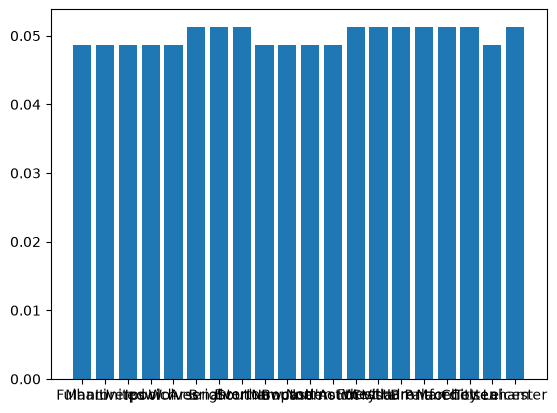

In [48]:
import matplotlib.pyplot as plt
plt.bar(r_networkx.keys(), r_networkx.values())

## 3.5 Check against networkx implementation


In [50]:
r_networkx = np.array(list(r_networkx.values()))
np.all(np.isclose(r_networkx,r))

np.True_

## 4. PageRank Sparse Iteration
Of course, the real cleverness in PageRank is the insight that you don't need to explictly construct the full matrix, by exploiting this is a graph problem. Use the starter code below to complete a function which performs a single step of PageRank without the dense matrix.

In [ ]:
def pagerank_step(G,r,d=0.85): 
    n = G.number_of_nodes()
    r_next = np.zeros(n,dtype=np.float32)

    #Fill all entries in r_next with the teleportation weights
    r_next = (1-d) / n * np.ones(n,dtype=np.float32)


    #Then, iterate over all vertices 
    #Propagate each vertex influence to its out-neighbors. 
    #Vertices with outdegree 0 should be handled differently. 
    for i, v in enumerate(G.nodes()):
        
        if G.out_degree(v) == 0:
            r_next += d * r[i] / n

        else:
            for neighbor in G.successors(v):
                j = list(G.nodes()).index(neighbor)
                r_next[j]  += d * r[i] / G.out_degree(v)

    return r_next

In [53]:
r_initial = np.ones(G.number_of_nodes()) / G.number_of_nodes()

r_new = pagerank_step(G, r_initial)

print(r_new)
print("Sum:", np.sum(r_new))

[0.04875001 0.04875001 0.04875001 0.04875001 0.04875001 0.05125001
 0.05125001 0.05125001 0.04875001 0.04875001 0.04875001 0.04875001
 0.05125001 0.05125001 0.05125001 0.05125001 0.05125001 0.05125001
 0.04875001 0.05125001]
Sum: 1.0


## 4.5 PageRank Sparse Power Iteration
Again, write a function which iteratively updates a vector until convergence

In [54]:
def PageRank_Sparse(G,d=0.85, tol=1e-6, max_iter=200):
    n = G.number_of_nodes()

    r = np.ones(n, dtype=np.float32) / n
    r_old = np.ones(n,dtype=np.float32) / n

    for index in range(max_iter):
        r_old = r.copy()

        r = pagerank_step(G,r,d)

        if np.linalg.norm(r - r_old, ord=1) <tol: break

    return r

Again, do a small sanity check against your previous and networkx implmentation.

In [56]:
# your code here
r_matrix = PageRank(G)
r_sparse = PageRank_Sparse(G)

r_networkx_dict = nx.pagerank(G, alpha=0.85)
r_networkx = np.array([
    r_networkx_dict[v] for v in G.nodes()
])

print("Matrix vs Sparse:",
      np.allclose(r_matrix, r_sparse, atol=1e-5))

print("Matrix vs NetworkX:",
      np.allclose(r_sparse, r_networkx, atol=1e-5))

print("Sum of Sparse PageRank:", np.sum(r_sparse))

Matrix vs Sparse: True
Matrix vs NetworkX: True
Sum of Sparse PageRank: 1.0000002


## Sparse vs. Full 
You should conduct the below results on the `Wiki-Vote.txt` data (edgelist). This data includes a directed edge A -> B if user A voted to promote user B to an admin role on Wikipedia.

You can verify that such a large graph will be very slow (or even run out of memory) on the full dense matrix implementation.

## 5. Results: top nodes by PageRank

### Task
- Print the top-10 nodes by PageRank score
- Include their scores

Write a short 2-3 sentences on how these scores can be interpreted in your data.


In [ ]:
G = nx.read_edgelist(
    "Wiki-Vote.txt",
    create_using=nx.DiGraph(),
    nodetype=int
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 7115
Number of edges: 103689


In [60]:
r_sparse = PageRank_Sparse(G)

print("PageRank calculated!")
print("Sum:", np.sum(r_sparse))

PageRank calculated!
Sum: 1.0000007


In [61]:
r_sparse = PageRank_Sparse(G)

pagerank_scores = list(zip(G.nodes(), r_sparse))

top10 = sorted(pagerank_scores, key=lambda x: x[1], reverse=True)[:10]

print("Top 10 nodes by PageRank:")
for rank, (node,score) in enumerate(top10, start=1):
    print(f"{rank}. Node {node}: {score:.8f}")

Top 10 nodes by PageRank:
1. Node 4037: 0.00460718
2. Node 15: 0.00367987
3. Node 6634: 0.00358679
4. Node 2625: 0.00328366
5. Node 2398: 0.00260864
6. Node 2470: 0.00252377
7. Node 2237: 0.00249663
8. Node 4191: 0.00226785
9. Node 7553: 0.00216973
10. Node 5254: 0.00215010


**your interpretation**

The top 10 nodes have the highest PageRank scores in the Wikipedia voting network. This indicates that these users received votes from other influential users, meaning their importance depends not only on the number of incoming votes but also on the importance of those who voted for them. Therefore, these nodes can be considered particularly influential in the Wikipedia administrator promotion voting network.

## 6. Light analysis

### 6.1 Distribution of PageRank scores
Plot a histogram of PageRank scores.

Questions to answer:
- Is the distribution highly skewed?
- Do most nodes have very small score?


Text(0.5, 1.0, 'Distribution of PageRank Scores')

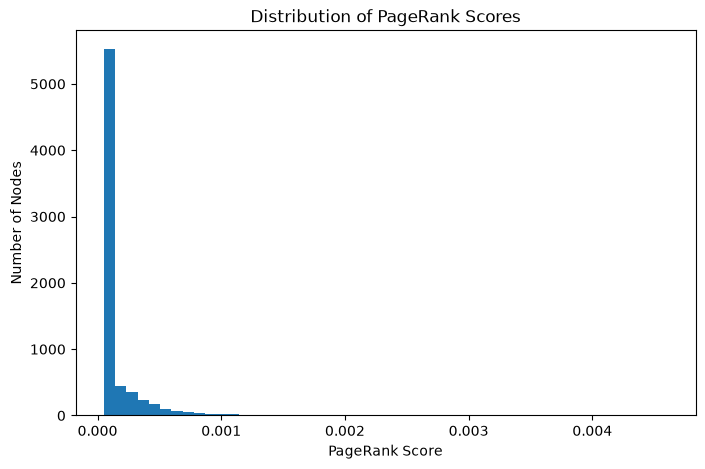

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(r_sparse, bins=50)

plt.xlabel("PageRank Score")
plt.ylabel("Number of Nodes")
plt.title("Distribution of PageRank Scores")
plt.show()


Answer: The distribution of PageRank scores is highly right-skewed. Most nodes have very small PageRank scores, as shown by the high bar on the left. The number of nodes decreases as the PageRank score increases, meaning only a small number of nodes have relatively high importance in the network.

### 6.2 Compare damping factors

Run PageRank with different damping factors and compare:
- `d = 0.70`, `0.85`, `0.95`

Tasks:
1. Compute rank vectors for each `d`
2. Compare the **top-10 overlap** between settings
3. Compute L1 distances between the resulting rank vectors

Answer briefly:
- Which nodes are stable across damping factors?
- Does higher `d` concentrate more probability on a smaller set of nodes?


In [65]:
r_070 = PageRank_Sparse(G, d=0.70)
r_085 = PageRank_Sparse(G, d=0.85)
r_095 = PageRank_Sparse(G, d=0.95)

nodes = list(G.nodes())

top_070 = [nodes[i] for i in np.argsort(r_070)[-10:][::-1]]
top_085 = [nodes[i] for i in np.argsort(r_085)[-10:][::-1]]
top_095 = [nodes[i] for i in np.argsort(r_095)[-10:][::-1]]

print("Top 10 for d=0.70:", top_070)
print("Top 10 for d=0.85:", top_085)
print("Top 10 for d=0.95:", top_095)

print("Overlap 0.70 vs 0.85:", len(set(top_070) & set(top_085)))
print("Overlap 0.70 vs 0.95:", len(set(top_070) & set(top_095)))
print("Overlap 0.85 vs 0.95:", len(set(top_085) & set(top_095)))

print("L1 distance 0.70 vs 0.85:",
      np.linalg.norm(r_070 - r_085, ord=1))

print("L1 distance 0.70 vs 0.95:",
      np.linalg.norm(r_070 - r_095, ord=1))

print("L1 distance 0.85 vs 0.95:",
      np.linalg.norm(r_085 - r_095, ord=1))

print("Top-10 probability mass:")
print("d=0.70:", sum(sorted(r_070, reverse=True)[:10]))
print("d=0.85:", sum(sorted(r_085, reverse=True)[:10]))
print("d=0.95:", sum(sorted(r_095, reverse=True)[:10]))

Top 10 for d=0.70: [4037, 15, 2625, 6634, 2470, 2237, 2398, 1186, 4191, 5254]
Top 10 for d=0.85: [4037, 15, 6634, 2625, 2398, 2470, 2237, 4191, 7553, 5254]
Top 10 for d=0.95: [4037, 6634, 15, 2625, 2398, 2237, 4191, 2470, 7553, 5254]
Overlap 0.70 vs 0.85: 9
Overlap 0.70 vs 0.95: 9
Overlap 0.85 vs 0.95: 10
L1 distance 0.70 vs 0.85: 0.151647
L1 distance 0.70 vs 0.95: 0.25267
L1 distance 0.85 vs 0.95: 0.101637945
Top-10 probability mass:
d=0.70: 0.025816077
d=0.85: 0.029374225
d=0.95: 0.031726252


Answer:
The top-10 nodes are relatively stable across different damping factors, with 9 or 10 nodes overlapping between the settings. Node 4037 consistently has the highest PageRank score, showing that its position is stable regardless of the damping factor. The L1 distances indicate that changing the damping factor affects the PageRank scores, especially between 0.70 and 0.95. Furthermore, the top-10 probability mass increases from 0.0258 to 0.0317 as the damping factor increases, suggesting that higher damping concentrates more probability among the most important nodes.

### 6.3 Relationship with out-degree

Compute correlation between PageRank and out-degree.

Questions:
- Are high PageRank nodes necessarily high out-degree nodes?
- What do you observe in the scatter plot?


Correlation between PageRank and out-degree: 0.25380581547231945


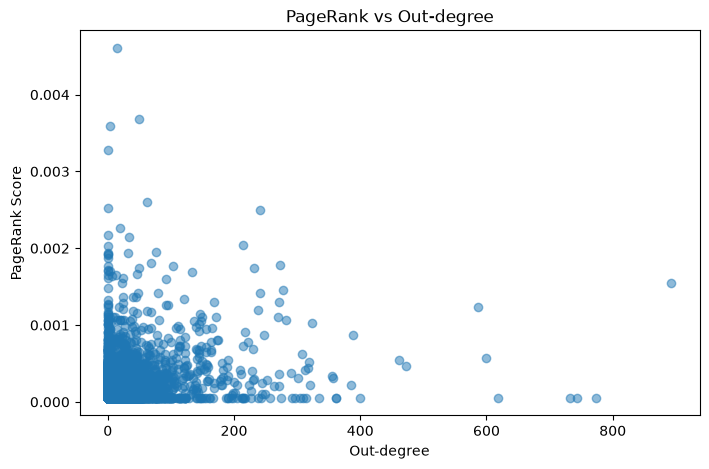

In [67]:
nodes = list(G.nodes())
out_degrees = np.array([G.out_degree(v) for v in nodes])

correlation = np.corrcoef(r_sparse, out_degrees)[0,1]

print("Correlation between PageRank and out-degree:", correlation)

plt.figure(figsize=(8, 5))

plt.scatter(out_degrees, r_sparse, alpha=0.5)

plt.xlabel("Out-degree")
plt.ylabel("PageRank Score")
plt.title("PageRank vs Out-degree")

plt.show()

Answer: The correlation between PageRank and out-degree is approximately 0.254, indicating a weak positive relationship. The scatter plot shows that most nodes have relatively low out-degree and low PageRank scores. Some nodes have high out-degree but low PageRank, while others achieve high PageRank with relatively few outgoing edges. Therefore, high PageRank nodes are not necessarily high out-degree nodes, because PageRank also depends on incoming links and the importance of the nodes linking to them.